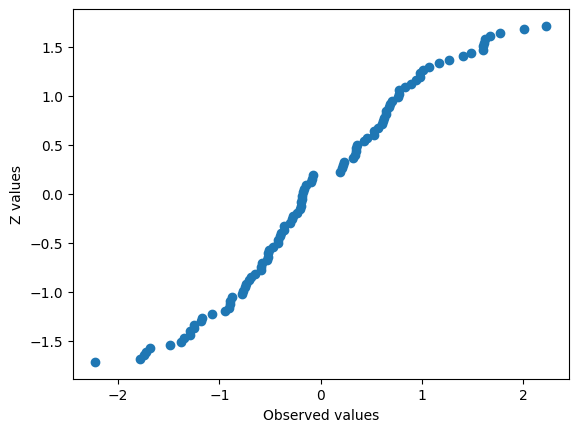

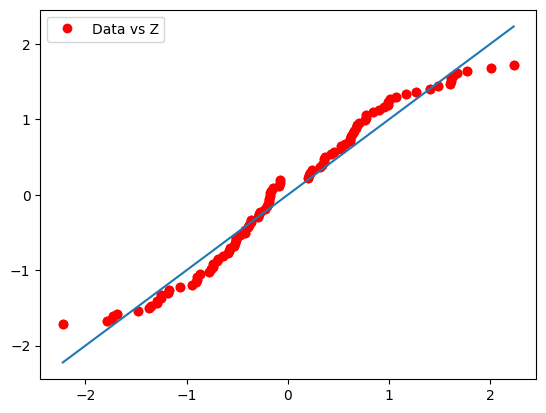

In [1]:
from scipy.stats import zscore
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
#its just an example npp of original values v/s theortical values(z scores)
def npp(data):
    data = sorted(data)
    p = [(data.index(i)-0.5)/len(data) for i in data]
    z = zscore(p)

  # Plot scatter plot of observed values vs Z-values
    plt.scatter(data, z)
    plt.ylabel('Z values')
    plt.xlabel('Observed values')
    plt.show()
  # Plot same data using red dots and add legend
    plt.plot(data, z, 'ro', label='Data vs Z')
    plt.legend()
  # Plot line of best fit
    plt.plot(data,  z,'ro',data,  data)
    plt.show()

#n datapoints
n = 100
data = np.random.randn(n)
npp(data)

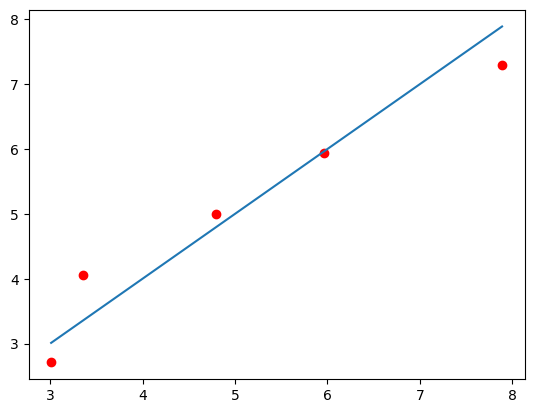

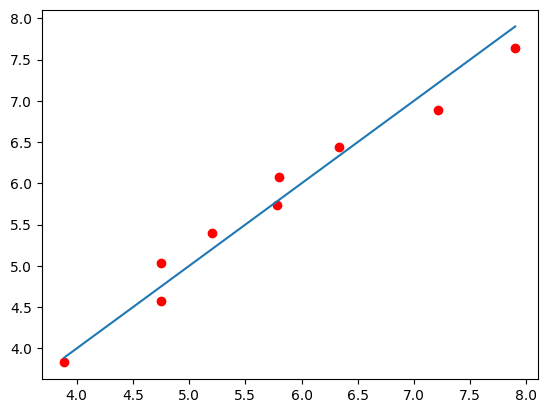

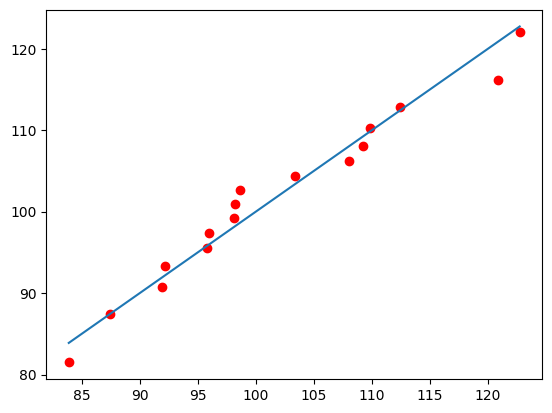

In [2]:

X1 = [3.01, 3.35, 4.79, 5.96, 7.89]

X2 = [3.89, 4.75, 4.75, 5.20, 5.78, 5.80, 6.33, 7.21, 7.90]

X3 = [108.047, 109.249, 103.385, 112.454, 95.780,  122.734, 109.842 , 120.858,
      98.604, 98.122,  95.971, 98.173,   87.437 , 91.884, 92.193,  83.882]
def npp1(data):

    p =[]   # Initialize list for cumulative probabilities (percentiles)
    t =[]   # Initialize list for theoretical quantiles

    data = np.sort(np.array(data))   # Sorting is essential for quantile comparison

    p = [(i - 0.5)/len(data) for i in range(1, len(data)+1)]   # Calculate plotting positions


    t = [norm.ppf(i, np.mean(data), np.std(data)) for i in p] #Computes the theoretical quantiles based on the normal distribution with mean and standard deviation calculated from the data. norm.ppf is the Percent-Point Function
    plt.plot(data, t, 'ro', data, data)
    plt.show()

npp1(X1)
npp1(X2)
npp1(X3)

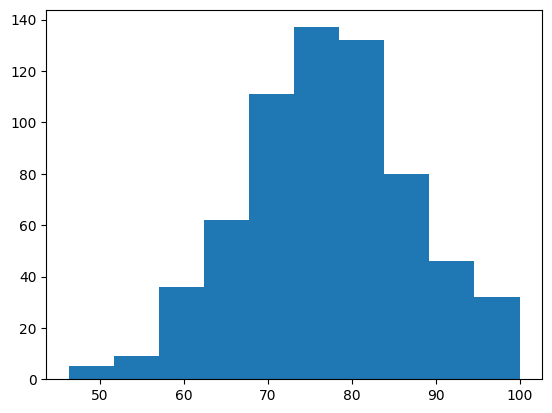

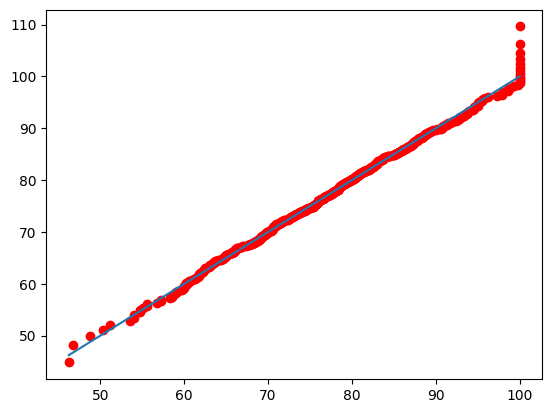

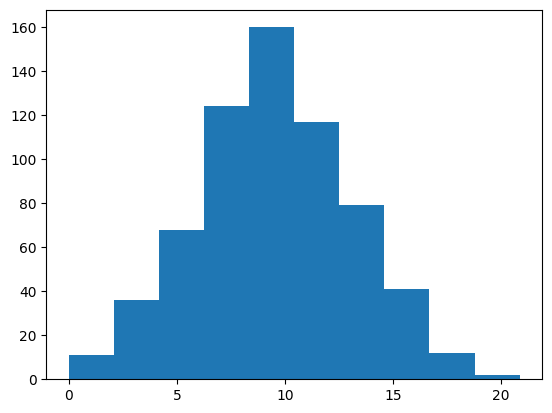

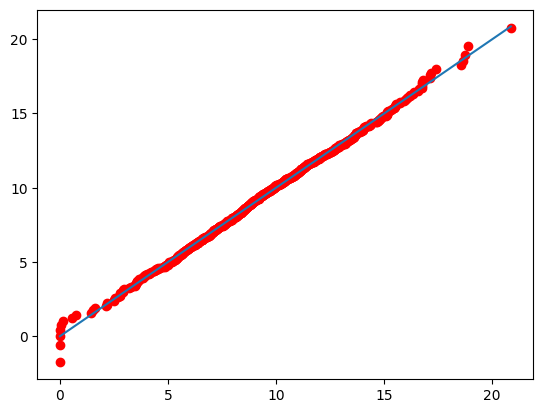

In [4]:
import pandas as pd

df = pd.read_csv('/content/Dataset_NPP.csv')
plt.hist(df.Attendance)
plt.show()
npp1(df.Attendance)


plt.hist(df.Study_Hours)
plt.show()
npp1(df.Study_Hours)

In [5]:
import csv
import pandas as pd
from random import sample

df = pd.read_csv('/content/Dataset_sampling.csv')

In [6]:
#simple random sampling
no_of_elements = 10
random_index = sample(range(df.shape[0]), no_of_elements)
print(random_index)
print(df.iloc[random_index])

[160, 174, 295, 281, 199, 18, 126, 184, 90, 16]
    Student_ID Department  Gender   Age   GPA  Credits_Completed  Attendance  \
160      S1135         ME    Male  18.0  7.57              140.0       52.85   
174      S1160         ME    Male  23.0  7.47              140.0       93.92   
295      S1124        CSE  Female  22.0  6.51               58.0       83.05   
281      S1256        CSE  Female  23.0  6.64               54.0       60.26   
199      S1146         CE    Male  24.0  7.27              140.0       66.34   
18       S1069         CE    Male  22.0  9.18              140.0       87.59   
126      S1344        ECE    Male  22.0  7.79              140.0       66.80   
184      S1030         ME  Female  18.0  7.43              140.0       65.19   
90       S1281        EEE  Female  24.0  8.11              140.0       88.54   
16       S1175        ECE  Female  24.0  9.25              140.0       45.32   

    Scholarship  
160          No  
174         Yes  
295          No  

In [7]:
#systematic sampling
Kth = 100
index = [i for i in range(df.shape[0]) if i%Kth==0]
print(df.iloc[index])

    Student_ID Department  Gender   Age    GPA  Credits_Completed  Attendance  \
0        S1152        CSE  Female  20.0  10.00              140.0       65.54   
100      S1254        CSE    Male  19.0   7.99              140.0       61.27   
200      S1010         CE    Male  23.0   7.26              140.0       61.43   
300      S1292        CSE  Female  20.0   6.42               44.0       72.00   

    Scholarship  
0            No  
100          No  
200         Yes  
300          No  


In [8]:
# #stratified sampling
# #stratas formed based on Department
# no_of_elements = 4        #number of elements in each strata


from random import sample

no_of_elements = 4
unique = list(df['Department'].dropna().unique())   # remove NaN
print('stratas :', unique, '\n')

index_set = [
    sample(
        list(df.index[df['Department'] == i]),
        min(no_of_elements, len(df.index[df['Department'] == i]))
    )
    for i in unique
]

index = [j for i in index_set for j in i]
print(df.loc[index])


stratas : ['CSE', 'ECE', 'ME', 'EEE', 'CE'] 

    Student_ID Department  Gender   Age    GPA  Credits_Completed  Attendance  \
325      S1313        CSE    Male  19.0   6.01               83.0       84.88   
333      S1018        CSE  Female  23.0   5.83               81.0       83.43   
229      S1302        CSE    Male  22.0   7.07               67.0       75.83   
276      S1118        CSE  Female  24.0   6.71               61.0       79.19   
1        S1260        ECE    Male  18.0  10.00              140.0       73.51   
226      S1057        ECE  Female  21.0   7.08               91.0       83.25   
285      S1027        ECE    Male  18.0   6.60              130.0       72.97   
241      S1318        ECE  Female  23.0   6.98               37.0       70.42   
153      S1214         ME  Female  22.0   7.61              140.0       71.83   
102      S1181         ME    Male  19.0   7.99              140.0       82.80   
237      S1054         ME  Female  21.0   7.01              107

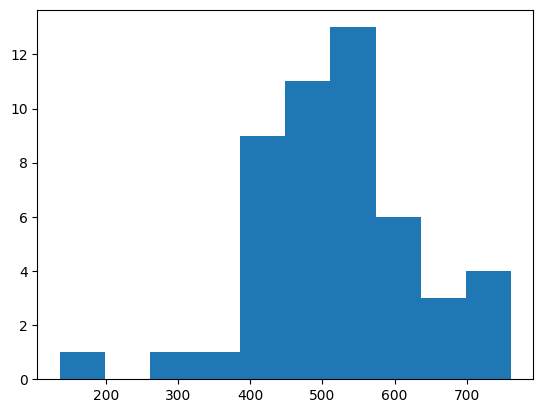

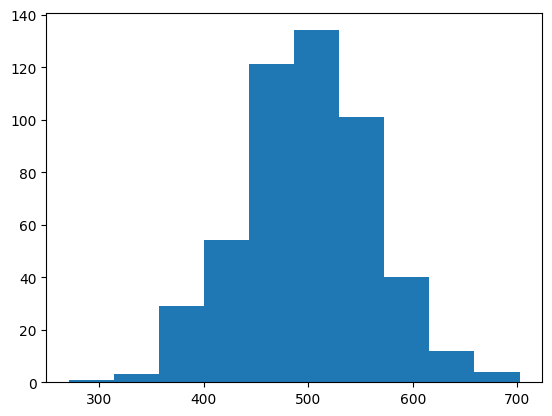

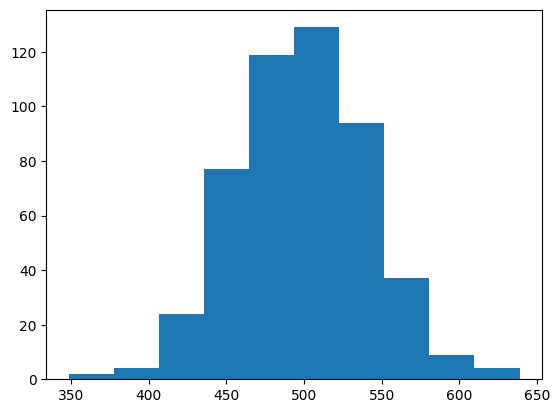

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from random import sample
from statistics import mean

def plot(arr, N, n_samples):
    x = []
    for i in range(1, n_samples):
        #to find N samples from the arr
        smp = sample(arr, N)
        mu = mean(smp)
        x.append(mu)
    plt.hist(x)
    plt.show()

#example data(population)
arr = [i for i in range(1000)]

#variations
plot(arr, 5, 50)
plot(arr, 20, 500)
plot(arr, 50, 500)
#so as number of samples(n_sample) increases the distribution becomes normal
#so as sample size increases the flatness of the distribution decreses